# 03 · Model experiments

**Goal (Phase 7, step 7.12):** write down which model won, by how much, and where it fails.

Every number below is read from the saved results (`models/*.json`, `reports/`, the MLflow store) or recomputed
with the project's own code. Nothing is typed in by hand. Rebuild everything with `python pipelines/run_all.py`;
the 7.4 / 7.5 comparison runs need `python pipelines/run_training.py --experiments` once.

| Step | What | Saved in |
|---|---|---|
| 7.3 | LightGBM median per family, raw vs relative target | MLflow |
| 7.4 | 10th / 90th percentile models, coverage | MLflow |
| 7.5 | ETS and SARIMAX per user | MLflow |
| 7.6 | Optuna tuning, checked on unseen months | `models/forecast_params.json` |
| 7.7 | SHAP explanations | `reports/` |
| 7.8 | Champion rule per series | `models/champions.json` |
| 7.9 | Export + registry | `models/forecaster_*.joblib`, `models/model_meta.json` |
| 7.10 | Anomaly model | `models/anomaly.joblib`, `models/anomaly_meta.json` |

> Data is **synthetic** (300 generated users, Oct 2023 - Sep 2026).

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT))
from src.evaluation.metrics import coverage, mae
from src.features.build_features import build_features
from src.forecasting.model import BASELINES, apply_champions
from src.training.train_forecaster import FAMILY_MODE, backtest_family_quantiles, saved_params
from src.utils.helpers import load_config, resolve_path

config = load_config()
MODELS = resolve_path(config["paths"]["models"])
load = lambda name: json.loads((MODELS / name).read_text())
champions, meta, tuning, anomaly = (load("champions.json"), load("model_meta.json"),
                                    load("forecast_params.json"), load("anomaly_meta.json"))
monthly = pd.read_parquet(resolve_path(config["paths"]["data_processed"]) / config["processed"]["monthly_file"])
users = pd.read_csv(resolve_path(config["paths"]["data_raw"]) / config["synthetic"]["users_file"])
table, info = build_features(monthly)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#e1e0d9", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "font.size": 10})
euro = lambda v: f"€{v:,.2f}"
print(f"Exported champion v{meta['version']} ({meta['created_at'][:10]}) · trained on {meta['training_data']['rows']:,} rows, "
      f"{meta['training_data']['target_months']} · {len(meta['feature_columns'])} features")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Exported champion v1 (2026-10-15) · trained on 126,000 rows, 2023-11 to 2026-09 · 15 features


## 1. Which model won, per series (step 7.8)

LightGBM becomes champion for a series only if its MAE is at least the threshold below the **best** of the three
baselines, over all rolling-backtest months on exactly the same forecasts. Otherwise that baseline stays.

In [2]:
threshold = champions["threshold"]
rows = []
for family, f in champions["families"].items():
    for series, s in f["series"].items():
        rows.append({"series": series, "champion": s["champion"], "lightgbm_mae": s["lightgbm_mae"],
                     "best_baseline": s["best_baseline"], "baseline_mae": s["baseline_mae"], "improvement": s["improvement"]})
per_series = pd.DataFrame(rows).sort_values("improvement", ascending=False, ignore_index=True)
print(champions["rule"], "·", f"test months {champions['families']['spend']['test_months']}")
display(per_series.style.format({"lightgbm_mae": euro, "baseline_mae": euro, "improvement": "{:+.1%}"})
        .hide(axis="index"))

LightGBM is champion only if its MAE is >= 10% below the best baseline · test months 2024-11 to 2026-09


series,champion,lightgbm_mae,best_baseline,baseline_mae,improvement
expenses:Health,lightgbm,€34.18,mean_3,€44.28,+22.8%
expenses:Leisure,lightgbm,€91.80,same_month_last_year,€112.68,+18.5%
expenses:Transport,lightgbm,€79.32,same_month_last_year,€93.43,+15.1%
income,lightgbm,€411.72,mean_3,€460.96,+10.7%
expenses:Dining,mean_3,€44.04,mean_3,€48.10,+8.5%
expenses:Shopping,same_month_last_year,€76.42,same_month_last_year,€80.26,+4.8%
expenses,same_month_last_year,€242.09,same_month_last_year,€243.81,+0.7%
expenses:Subscriptions,last_month,€0.37,last_month,€0.00,+0.0%
expenses:Groceries,mean_3,€24.53,mean_3,€23.23,-5.6%
expenses:Utilities,mean_3,€2.40,mean_3,€1.86,-29.4%


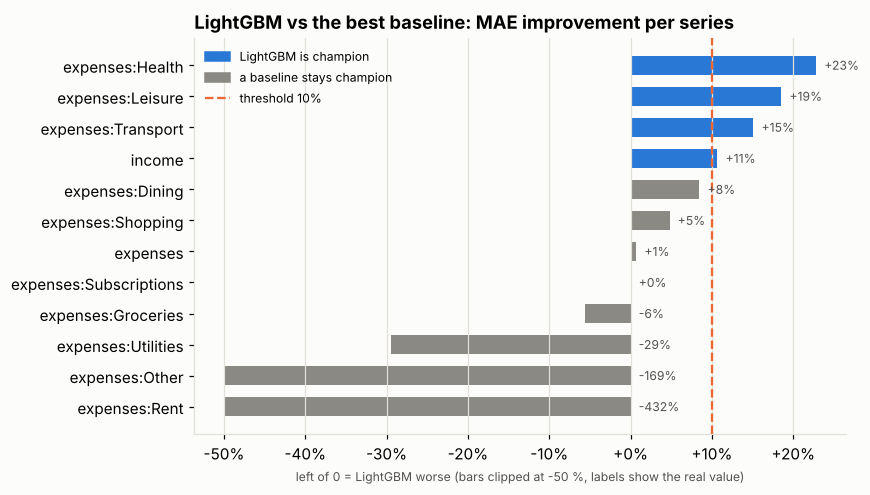

In [3]:
shown = per_series.copy()
shown["clipped"] = shown["improvement"].clip(lower=-0.5)
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = [BLUE if c == "lightgbm" else GREY for c in shown["champion"]]
ax.barh(shown["series"], shown["clipped"], color=colors, height=0.6)
ax.axvline(threshold, color=ORANGE, linewidth=1.5, linestyle="--")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(color=BLUE, label="LightGBM is champion"), Patch(color=GREY, label="a baseline stays champion"),
                   Line2D([], [], color=ORANGE, linestyle="--", label=f"threshold {threshold:.0%}")],
          loc="upper left", fontsize=8, frameon=False)
for y, (value, clipped) in enumerate(zip(shown["improvement"], shown["clipped"])):
    ax.text(max(clipped, 0) + 0.01, y, f"{value:+.0%}", va="center", fontsize=8, color="#52514e")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_title("LightGBM vs the best baseline: MAE improvement per series", loc="left")
ax.set_xlabel("left of 0 = LightGBM worse (bars clipped at -50 %, labels show the real value)", fontsize=8, color="#52514e")
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

## 2. The whole system on the backtest

Champion point forecast per series plus the LightGBM 10-90 % range, compared with two simpler set-ups:
the best baseline everywhere, and LightGBM everywhere. The **check** picks champions on the earlier half of the
test months only and scores that choice on the later half, so the selection cannot flatter itself.

In [4]:
rows = []
for family, f in champions["families"].items():
    s, c = f["system"], f["check"]
    rows.append({"family": family, "champion system": s["mae"], "best baseline everywhere": s["baseline_only_mae"],
                 "LightGBM everywhere": s["lightgbm_only_mae"], "range coverage": s["coverage"],
                 "check: champions": c["check_mae_champions"], "check: best baseline": c["check_mae_best_baseline"],
                 "check: LightGBM": c["check_mae_lightgbm"], "same champion": f"{c['agree']}/{c['series']}"})
system = pd.DataFrame(rows)
money = [c for c in system.columns if c not in ("family", "range coverage", "same champion")]
display(system.style.format({**{c: euro for c in money}, "range coverage": "{:.1%}"}).hide(axis="index"))
for family, f in champions["families"].items():
    print(f"{family}: range width - {f['width_reason']}")

family,champion system,best baseline everywhere,LightGBM everywhere,range coverage,check: champions,check: best baseline,check: LightGBM,same champion
income,€411.72,€460.96,€411.72,77.6%,€407.33,€455.64,€407.33,1/1
spend,€55.23,€59.33,€55.72,85.1%,€51.71,€58.81,€51.35,11/11


income: range width - raw width kept: factor 1.30 would move check-month coverage 85.0% -> 92.9%, further from 80%
spend: range width - calibration chose factor 1.00 (no change): check-month coverage 82.0%


## 3. Recomputing the backtest for a closer look

The JSON files hold totals. To see *where* the system errs, the backtest is re-run here with the exported
settings (about 2 minutes): LightGBM 10/50/90 % models per family, the champion per series from
`champions.json`, the three baselines, and each user's type.

In [5]:
keys = ["user_id", "series", "month"]
params = saved_params()
parts = []
for family in ("income", "spend"):
    f = champions["families"][family]
    predictions = backtest_family_quantiles(table, family, FAMILY_MODE[family], info["feature_columns"],
                                            params=params.get(family))
    rows = table.set_index(keys).loc[pd.MultiIndex.from_frame(predictions[keys])].reset_index()
    final = apply_champions(rows, predictions["lower"].to_numpy(), predictions["predicted"].to_numpy(),
                            predictions["upper"].to_numpy(),
                            {s: v["champion"] for s, v in f["series"].items()}, f["width_factor"])
    part = predictions[keys + ["target_month", "actual"]].assign(
        lightgbm=predictions["predicted"].to_numpy(), system=final["predicted"].to_numpy(),
        lower=final["lower"].to_numpy(), upper=final["upper"].to_numpy(), champion=final["champion"].to_numpy())
    for name, forecast in BASELINES.items():
        part[name] = forecast(rows).to_numpy()
    part["best_baseline"] = part[list(BASELINES)].to_numpy()[
        np.arange(len(part)), part["series"].map({s: list(BASELINES).index(v["best_baseline"]) for s, v in f["series"].items()})]
    parts.append(part)
bt = pd.concat(parts, ignore_index=True).merge(users[["user_id", "archetype"]], on="user_id")
bt["group"] = bt["series"].where(bt["series"].isin(["income", "expenses"]), "category")
same = abs(mae(bt.loc[bt.series != "income", "actual"], bt.loc[bt.series != "income", "system"])
           - champions["families"]["spend"]["system"]["mae"]) < 0.01
print(f"{len(bt):,} forecasts · spend system MAE matches champions.json: {same}")

82,800 forecasts · spend system MAE matches champions.json: True


## 4. Where it fails: by user type

MAE of the champion system next to the best baseline, and how often the real value fell inside the range.

In [6]:
def summary(part):
    return pd.Series({"n": len(part), "system": mae(part["actual"], part["system"]),
                      "best baseline": mae(part["actual"], part["best_baseline"]),
                      "last month": mae(part["actual"], part["last_month"]),
                      "coverage": coverage(part["actual"], part["lower"], part["upper"])})

by_type = bt.groupby(["group", "archetype"]).apply(summary).reset_index()
by_type["system vs best baseline"] = 1 - by_type["system"] / by_type["best baseline"].replace(0, np.nan)
display(by_type.style.format({"n": "{:,.0f}", "system": euro, "best baseline": euro, "last month": euro,
                              "coverage": "{:.1%}", "system vs best baseline": "{:+.1%}"}, na_rep="baseline exact")
        .hide(axis="index"))

group,archetype,n,system,best baseline,last month,coverage,system vs best baseline
category,freelancer,"17,480",€35.67,€40.13,€158.65,84.9%,+11.1%
category,salaried_family,"17,020",€47.10,€52.29,€77.93,85.7%,+9.9%
category,salaried_single,"25,530",€35.32,€40.01,€55.11,85.0%,+11.7%
category,student,"8,970",€20.38,€23.16,€27.59,86.5%,+12.0%
expenses,freelancer,"1,748",€243.04,€243.04,"€1,151.99",78.6%,+0.0%
expenses,salaried_family,"1,702",€313.73,€313.73,€461.81,87.8%,+0.0%
expenses,salaried_single,"2,553",€233.70,€233.70,€318.40,81.6%,+0.0%
expenses,student,897,€141.39,€141.39,€157.40,81.5%,+0.0%
income,freelancer,"1,748","€1,587.27","€1,767.02","€2,134.05",68.1%,+10.2%
income,salaried_family,"1,702",€23.30,€25.11,€12.56,81.7%,+7.2%


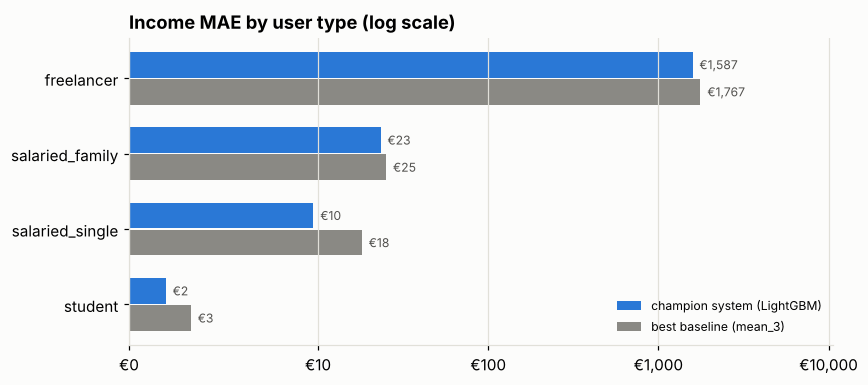

In [7]:
income = by_type[by_type["group"] == "income"].set_index("archetype")
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(income))
ax.barh(y - 0.18, income["system"], height=0.34, color=BLUE, label="champion system (LightGBM)")
ax.barh(y + 0.18, income["best baseline"], height=0.34, color=GREY,
        label=f"best baseline ({champions['families']['income']['series']['income']['best_baseline']})")
for i, (s, b) in enumerate(zip(income["system"], income["best baseline"])):
    ax.text(s, i - 0.18, f"  €{s:,.0f}", va="center", fontsize=8, color="#52514e")
    ax.text(b, i + 0.18, f"  €{b:,.0f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, income.index)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, income[["system", "best baseline"]].max().max() * 6)
ax.xaxis.set_major_formatter(lambda v, _: f"€{v:,.0f}")
ax.invert_yaxis(); ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_title("Income MAE by user type (log scale)", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

In [8]:
steady = bt[(bt["series"] == "income") & (bt["archetype"] != "freelancer")]
exact = (steady["last_month"] == steady["actual"]).mean()
print(f"Steady incomes (salaried + students): last month's value is exactly right in {exact:.1%} of {len(steady):,} forecasts;")
print(f"MAE: champion (LightGBM, chosen for income as a whole) {euro(mae(steady['actual'], steady['system']))}, "
      f"last month {euro(mae(steady['actual'], steady['last_month']))}, 3-month average {euro(mae(steady['actual'], steady['mean_3']))}.")
free = bt[(bt["series"] == "income") & (bt["archetype"] == "freelancer")]
print(f"Freelancer income: MAE {euro(mae(free['actual'], free['system']))}, "
      f"{(free['actual'] == 0).mean():.1%} of months with no income at all, "
      f"range holds the real value {coverage(free['actual'], free['lower'], free['upper']):.1%} of the time.")

Steady incomes (salaried + students): last month's value is exactly right in 91.3% of 5,152 forecasts;
MAE: champion (LightGBM, chosen for income as a whole) €12.87, last month €8.91, 3-month average €17.83.
Freelancer income: MAE €1,587.27, 0.9% of months with no income at all, range holds the real value 68.1% of the time.


## 5. Errors over time
Monthly MAE of the champion system vs the best baseline, for total spending and the categories.

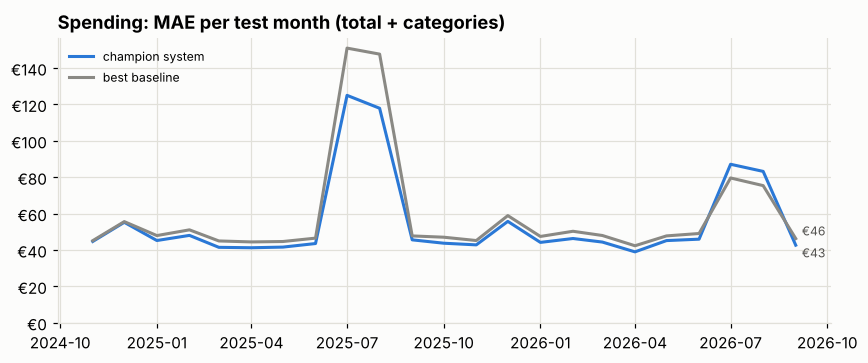

Months where the system did worst relative to the baseline:
              system  best baseline   gap
target_month                             
2026-08        83.23          75.41  7.82
2026-07        87.15          79.61  7.53
2024-12        55.24          55.63 -0.38

July + August: system MAE minus best-baseline MAE per series (positive = system worse):
year                  2025    2026
series                            
expenses:Leisure   -280.82  104.59
expenses:Dining       0.00    0.00
expenses              0.00    0.00
expenses:Groceries    0.00    0.00
expenses:Other        0.00    0.00


In [9]:
spend = bt[bt["series"] != "income"]
over_time = spend.groupby("target_month").apply(lambda p: pd.Series({
    "system": mae(p["actual"], p["system"]), "best baseline": mae(p["actual"], p["best_baseline"])}))
fig, ax = plt.subplots(figsize=(8, 3.4))
x = over_time.index.to_timestamp()
ax.plot(x, over_time["system"], color=BLUE, linewidth=2, label="champion system")
ax.plot(x, over_time["best baseline"], color=GREY, linewidth=2, label="best baseline")
ends = over_time.iloc[-1]
upper = ends.idxmax()
for column in ("system", "best baseline"):
    ax.annotate(f"€{ends[column]:,.0f}", (x[-1], ends[column]), xytext=(4, 5 if column == upper else -5),
                textcoords="offset points", fontsize=8, color="#52514e", va="center")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(lambda v, _: f"€{v:,.0f}")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.set_title("Spending: MAE per test month (total + categories)", loc="left")
fig.tight_layout(); plt.show()
worst = over_time.assign(gap=over_time["system"] - over_time["best baseline"]).sort_values("gap", ascending=False).head(3)
print("Months where the system did worst relative to the baseline:")
print(worst.round(2).to_string())
summer = spend[spend["target_month"].dt.month.isin([7, 8])]
by_series = summer.groupby([summer["target_month"].dt.year.rename("year"), "series"]).apply(
    lambda p: mae(p["actual"], p["system"]) - mae(p["actual"], p["best_baseline"])).unstack(0)
print("\nJuly + August: system MAE minus best-baseline MAE per series (positive = system worse):")
print(by_series.round(2).sort_values(by_series.columns[-1], ascending=False).head(5).to_string())

## 6. Classic models: ETS and SARIMAX (step 7.5)

One model per user and series, scored on income and total spending over the last 6 test months. The LightGBM
and baseline numbers are recomputed here on exactly the same rows.

In [10]:
import mlflow
from src.utils.helpers import mlflow_tracking_uri

last6 = sorted(bt["target_month"].unique())[-6:]
rows = []
for series in ("income", "expenses"):
    part = bt[(bt["series"] == series) & bt["target_month"].isin(last6)]
    best = min(BASELINES, key=lambda b: mae(part["actual"], part[b]))
    rows += [{"series": series, "model": f"best baseline ({best})", "mae": mae(part["actual"], part[best])},
             {"series": series, "model": "LightGBM", "mae": mae(part["actual"], part["lightgbm"])}]
try:
    mlflow.set_tracking_uri(mlflow_tracking_uri())
    runs = mlflow.search_runs(experiment_names=["forecast_income", "forecast_spend"])
    runs = runs[runs["tags.mlflow.runName"].str.match(r"^(ets|sarimax)_(income|expenses)$", na=False)]
    runs = runs.sort_values("start_time").groupby("tags.mlflow.runName").tail(1)
    for _, run in runs.iterrows():
        model, series = run["tags.mlflow.runName"].split("_")
        rows.append({"series": series, "model": model.upper(), "mae": run["metrics.mae"]})
except Exception as err:
    print("No ETS / SARIMAX runs in MLflow yet - run `python pipelines/run_training.py --experiments`.", err)
classic = pd.DataFrame(rows)
classic["vs best baseline"] = classic.groupby("series")["mae"].transform(lambda m: 1 - m / m.iloc[0])
display(classic.style.format({"mae": euro, "vs best baseline": "{:+.1%}"}).hide(axis="index"))
print(f"Test months: {last6[0]} to {last6[-1]}")

series,model,mae,vs best baseline
income,best baseline (mean_3),€465.55,+0.0%
income,LightGBM,€417.81,+10.3%
expenses,best baseline (same_month_last_year),€231.24,+0.0%
expenses,LightGBM,€235.63,-1.9%
income,ETS,€527.75,-13.4%
income,SARIMAX,€427.52,+8.2%
expenses,ETS,€259.43,-12.2%
expenses,SARIMAX,€346.85,-50.0%


Test months: 2026-04 to 2026-09


## 7. Forecast ranges (step 7.4)

The 10th and 90th percentile models should hold the real value about 80 % of the time. A width factor was
calibrated on the earlier test months and kept only if it also helped on the later ones.

In [11]:
rows = []
for family, f in champions["families"].items():
    part = bt[(bt["series"] == "income") == (family == "income")]
    rows.append({"family": family, "width factor": f["width_factor"],
                 "coverage": coverage(part["actual"], part["lower"], part["upper"]),
                 "mean width": float((part["upper"] - part["lower"]).mean()),
                 "below the range": float((part["actual"] < part["lower"]).mean()),
                 "above the range": float((part["actual"] > part["upper"]).mean())})
display(pd.DataFrame(rows).style.format({"coverage": "{:.1%}", "mean width": "€{:,.0f}", "width factor": "{:.2f}",
                                         "below the range": "{:.1%}", "above the range": "{:.1%}"}).hide(axis="index"))
cov = bt.groupby(["group", "archetype"]).apply(lambda p: coverage(p["actual"], p["lower"], p["upper"])).unstack()
display(cov.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0.6, vmax=1.0))

family,width factor,coverage,mean width,below the range,above the range
income,1.00,77.6%,"€1,035",7.9%,14.5%
spend,1.00,85.1%,€196,6.8%,8.1%


archetype,freelancer,salaried_family,salaried_single,student
group,,,,
category,84.9%,85.7%,85.0%,86.5%
expenses,78.6%,87.8%,81.6%,81.5%
income,68.1%,81.7%,79.5%,82.8%


## 8. Tuning (step 7.6)
The search was scored on 6 tune months; the last 6 months were kept unseen for the before/after check.

In [12]:
rows = [{"family": family, "settings used": f["source"], "hold-out months": f["holdout_months"],
         "default MAE": f["holdout_mae"]["default"], "tuned MAE": f["holdout_mae"]["tuned"],
         "tuned vs default": 1 - f["holdout_mae"]["tuned"] / f["holdout_mae"]["default"]}
        for family, f in tuning["families"].items()]
display(pd.DataFrame(rows).style.format({"default MAE": euro, "tuned MAE": euro, "tuned vs default": "{:+.1%}"})
        .hide(axis="index"))

family,settings used,hold-out months,default MAE,tuned MAE,tuned vs default
income,default,2026-04 to 2026-09,€418.53,€426.58,-1.9%
spend,default,2026-04 to 2026-09,€57.05,€57.26,-0.4%


## 9. What the models rely on (step 7.7)
Mean |SHAP| share per input for the forecasts of the last test month.

income: roll_mean_6 21%, income_volatility 21%, roll_std_6 13%, lag_12 9%, month_sin 8%
spend: lag_3 48%, lag_12 15%, lag_1 11%, series 10%, roll_mean_3 7%


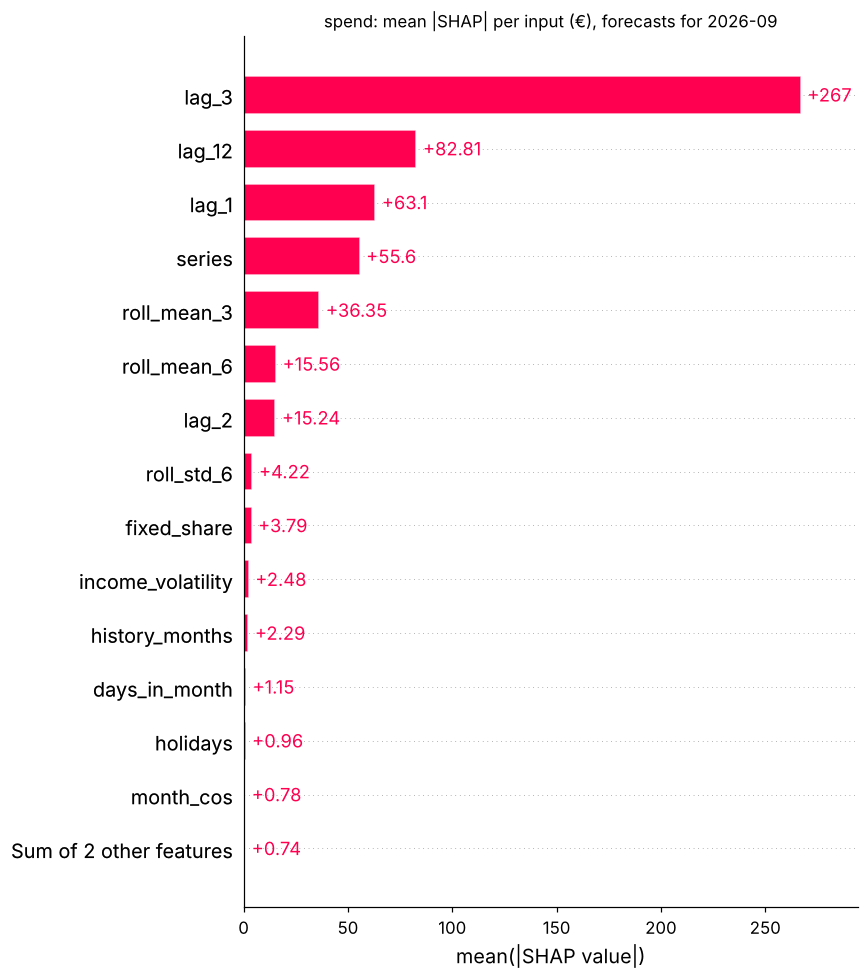

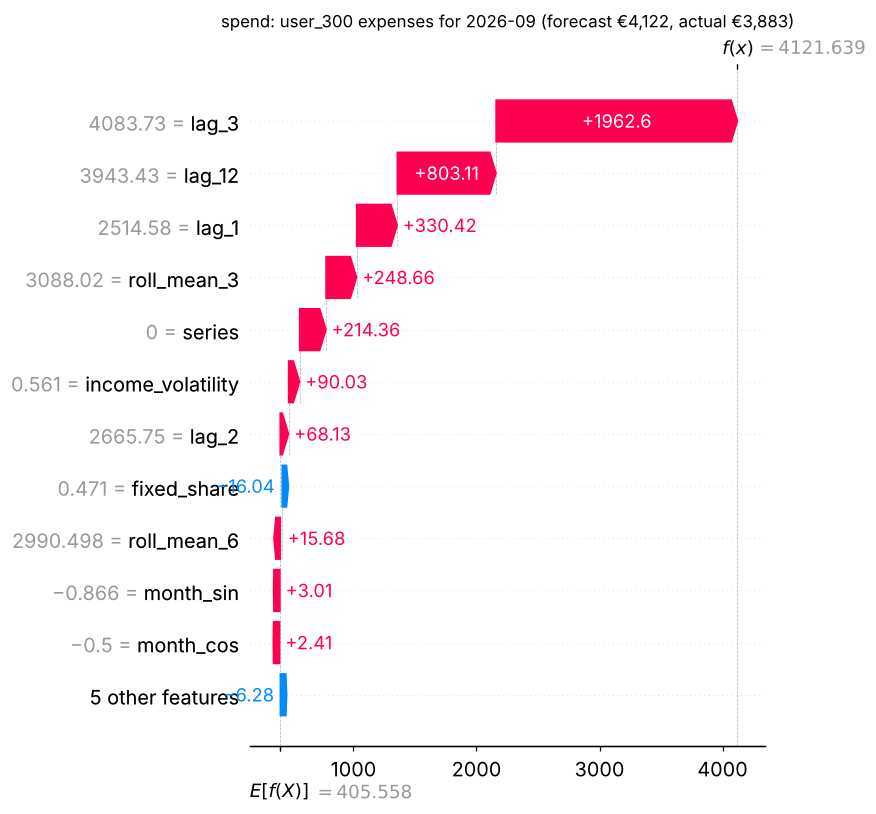

In [13]:
for family in ("income", "spend"):
    imp = pd.read_csv(ROOT / "reports" / f"shap_importance_{family}.csv")
    print(f"{family}: " + ", ".join(f"{r.feature} {r.share:.0%}" for r in imp.head(5).itertuples()))
display(Image(filename=str(ROOT / "reports" / "figures" / "shap_summary_spend.png"), width=560))
display(Image(filename=str(ROOT / "reports" / "figures" / "shap_example_spend.png"), width=560))

## 10. Anomaly model (step 7.10)
Scored on the test months against the generator's rare big costs plus planted duplicates and price rises.

In [14]:
kinds = ["shock", "duplicate", "price_rise"]
rows = []
for name, r in (("Isolation Forest", anomaly["test"]), ("simple rule", anomaly["rule_baseline"])):
    rows.append({"model": name, "flagged": r["flag_rate"], "precision": r["precision"], "recall": r["recall"],
                 **{f"recall {k}": r[f"recall_{k}"] for k in kinds}, "false alarms": r["false_alarm_rate"]})
display(pd.DataFrame(rows).style.format({c: "{:.1%}" for c in rows[0] if c != "model"}).hide(axis="index"))
print(f"Flags in the exported detector: {anomaly['flag_method']} ({anomaly['flag_method_reason']}) · "
      f"test months {anomaly['periods']['test']}")

model,flagged,precision,recall,recall shock,recall duplicate,recall price_rise,false alarms
Isolation Forest,3.4%,14.6%,63.7%,83.9%,98.8%,20.8%,2.9%
simple rule,1.4%,49.5%,87.7%,75.8%,100.0%,79.8%,0.7%


Flags in the exported detector: rule (validation F1: rule 0.686 vs forest 0.368) · test months 2025-10 to 2026-09


## 11. Summary in numbers
Generated from the results above.

In [15]:
f_inc, f_sp = champions["families"]["income"], champions["families"]["spend"]
lgbm = per_series[per_series["champion"] == "lightgbm"]
lines = [
    f"- LightGBM is champion for {len(lgbm)} of {len(per_series)} series: "
    + ", ".join(f"{s} ({i:+.0%})" for s, i in zip(lgbm["series"], lgbm["improvement"])) + ".",
    f"- Spending system MAE {euro(f_sp['system']['mae'])} vs {euro(f_sp['system']['baseline_only_mae'])} for the best "
    f"baseline everywhere ({1 - f_sp['system']['mae'] / f_sp['system']['baseline_only_mae']:+.1%}); on the later check months "
    f"{euro(f_sp['check']['check_mae_champions'])} vs {euro(f_sp['check']['check_mae_best_baseline'])}.",
    f"- Income MAE {euro(f_inc['system']['mae'])} vs {euro(f_inc['system']['baseline_only_mae'])} "
    f"({1 - f_inc['system']['mae'] / f_inc['system']['baseline_only_mae']:+.1%}), almost all of it freelancer income.",
    f"- Steady incomes: last month's value is exact in {exact:.0%} of cases; MAE {euro(mae(steady['actual'], steady['last_month']))} "
    f"with last month vs {euro(mae(steady['actual'], steady['system']))} with the champion.",
    f"- Range coverage: income {f_inc['system']['coverage']:.1%}, spending {f_sp['system']['coverage']:.1%} (target 80 %).",
    "- Tuning: " + ", ".join(f"{fam} uses {t['source']} settings (unseen months: default {euro(t['holdout_mae']['default'])}, "
                             f"tuned {euro(t['holdout_mae']['tuned'])})" for fam, t in tuning["families"].items()) + ".",
    f"- Anomalies: the {anomaly['flag_method']} decides the flags - recall {anomaly['rule_baseline']['recall']:.0%} at "
    f"precision {anomaly['rule_baseline']['precision']:.0%}, vs {anomaly['test']['recall']:.0%} / {anomaly['test']['precision']:.0%} for the forest.",
]
print("\n".join(lines))

- LightGBM is champion for 4 of 12 series: expenses:Health (+23%), expenses:Leisure (+19%), expenses:Transport (+15%), income (+11%).
- Spending system MAE €55.23 vs €59.33 for the best baseline everywhere (+6.9%); on the later check months €51.71 vs €58.81.
- Income MAE €411.72 vs €460.96 (+10.7%), almost all of it freelancer income.
- Steady incomes: last month's value is exact in 91% of cases; MAE €8.91 with last month vs €12.87 with the champion.
- Range coverage: income 77.6%, spending 85.1% (target 80 %).
- Tuning: income uses default settings (unseen months: default €418.53, tuned €426.58), spend uses default settings (unseen months: default €57.05, tuned €57.26).
- Anomalies: the rule decides the flags - recall 88% at precision 49%, vs 64% / 15% for the forest.


## Findings

**Which model won.** LightGBM is champion only where it clearly earns it: income and the three most irregular
spending categories (Health, Leisure, Transport). Everywhere else a simple baseline stays: same month last year
for total spending and Shopping, last month for Rent and Subscriptions, the 3-month average for Groceries, Dining
and Utilities. Picking the champions on the earlier test months gives exactly the same choice, so the selection is
stable and not a lucky draw (section 2).

**By how much.** Over the whole spending system the gain against the best baselines is modest but real, and it
holds on the later check months. For income the gain comes almost entirely from freelancers (section 4).
Neither ETS nor SARIMAX beats LightGBM on income; on total spending none of the models beats "same month last
year" (section 6). Tuning found nothing that survived the unseen months, so the default settings stay (section 8).

**Where it fails.**
- **Freelancer income** is the hardest series by far: the error is in the thousands of euro and the 10-90 % range
  holds the real value clearly less often than the 80 % target, with misses mostly on the high side (section 7).
  The range is honest about the uncertainty, but still too narrow for this group.
- **Steady salaries** are hurt by the per-series champion rule: LightGBM wins income as a whole because of the
  freelancers, but for salaried users and students "last month" is exact in most months and has a lower error
  than the champion (section 4). Phase 8 should use last month's value for incomes that have not changed
  recently (zero income volatility) and LightGBM only for the variable ones.
- **Holiday spending (Leisure in July and August)**: LightGBM beat the baseline by a lot in the first summer of
  the test period but lost in the second, when "same month last year" had a real summer to copy (section 5).
  A stronger yearly-seasonal signal for Leisure is a candidate improvement.
- **Rent, Other and Utilities** are near-deterministic (fixed amounts, the quarterly tax payment), so the
  baselines are close to exact and LightGBM only adds noise there; the champion rule correctly keeps them out.
- **Anomalies**: the Isolation Forest flags too much that is merely large (rent, tax) and misses subscription
  price rises; the simple rule is better on every type except big first payments in a category the user has
  never paid in before, which the rule cannot see (section 10).

**What this means for Phase 8.** The app should load the exported champion bundles, show the range next to the
point forecast, add the steady-income rule above, use the rule-based anomaly flags with the forest score for
ranking, and be explicit in the UI that freelancer income forecasts are rough.
